# Hello World

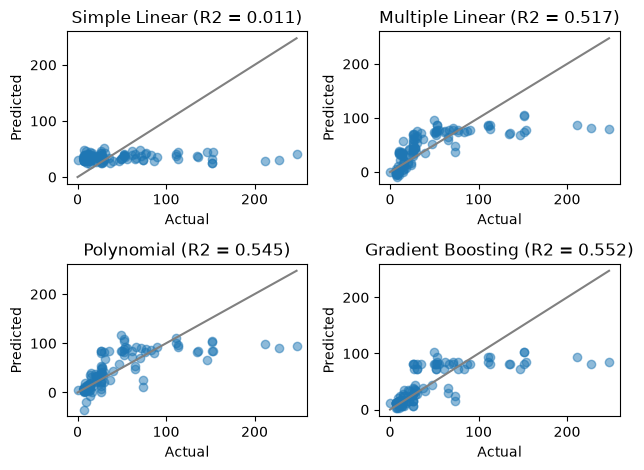

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 1. load + clean + split (80% train / 20% test)
df = pd.read_csv("titanic.csv")

df["Sex"] = (df["Sex"] == "male") * 1
df = df[["Age", "Pclass", "SibSp", "Parch", "Sex", "Fare"]].dropna()
df = df.sample(frac=1, random_state=42)
X = df[["Age", "Pclass", "SibSp", "Parch", "Sex"]].values
y = df["Fare"].values
n = int(len(df) * 0.8)
X_train, X_test, y_train, y_test = X[:n], X[n:], y[:n], y[n:]



# 2. linear regression: w = (X^T X)^-1 X^T y
def linear(X_train, y_train, X_test):
    X_train = np.column_stack([np.ones(len(X_train)), X_train])
    X_test = np.column_stack([np.ones(len(X_test)), X_test])
    w = np.linalg.pinv(X_train.T @ X_train) @ X_train.T @ y_train
    return X_test @ w
    
# 3. gradient boosting: keep adding a small "split into 2 groups" fix
def boost(X_train, y_train, X_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(X_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for j in range(X_train.shape[1]):
            for t in np.unique(X_train[:, j])[:-1]:
                left = X_train[:, j] <= t
                a, b = error[left].mean(), error[~left].mean()
                loss = ((error[left] - a) ** 2).sum() + ((error[~left] - b) ** 2).sum()
                if loss < best:
                    best, bj, bt, ba, bb = loss, j, t, a, b
        pred_train[X_train[:, bj] <= bt] += 0.1 * ba
        pred_train[X_train[:, bj] > bt] += 0.1 * bb
        pred_test[X_test[:, bj] <= bt] += 0.1 * ba
        pred_test[X_test[:, bj] > bt] += 0.1 * bb
    return pred_test
    
def boost(x_train, y_train, x_test):
    pred_train = np.full(len(y_train), y_train.mean())
    pred_test = np.full(len(x_test), y_train.mean())
    for _ in range(50):
        error = y_train - pred_train
        best = 1e18
        for i in range(x_train.shape[1]):
            left = x_train[:, i] <= t
            a, b = error[left].mean(), error[]



# 4. plot
def show(pos, name, y_pred):
    r2 = 1 - ((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()
    plt.subplot(2, 2, pos)
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([0, y_test.max()], [0, y_test.max()], "gray")
    plt.title(f"{name} (R2 = {r2:.3f})")
    plt.xlabel("Actual"); plt.ylabel("Predicted")

show(1, "Simple Linear", linear(X_train[:, :1], y_train, X_test[:, :1]))
show(2, "Multiple Linear", linear(X_train, y_train, X_test))
show(3, "Polynomial", linear(np.column_stack([X_train, X_train**2]), y_train, np.column_stack([X_test, X_test**2])))
show(4, "Gradient Boosting", boost(X_train, y_train, X_test))
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, r2_score


# 1. load + clean + split
df = pd.read_csv("titanic.csv")
df["Sex"] = (df["Sex"] == "male") * 1
cols = ["Age", "Pclass", "SibSp", "Parch", "Sex"]
df = df[cols + ["Survived", "Fare"]].dropna()
X_train, X_test, y_train, y_test = train_test_split(df[cols], df[["Survived", "Fare"]], test_size=0.2, random_state=42)

# 2. classification: 3 models + 1 better model (Gradient Boosting)
best_cls = GradientBoostingClassifier(random_state = 42)
classifiers = [("Logistic", LogisticRegression(max_iter=1000))
                ,("KNN", KNeighborsClassifier())
                ,("DecisionTree", DecisionTreeClassifier(max_depth=4))
                , ("Gradient Boosting", best_clf)]
for name, model in classifiers:
    pred = model.fit(x_train, y_train["Survived"]).predict(x_test)
    print(name, "accuracy:", round(accuracy_score(y_test["Survived"], pred), 3), "f1:", round(f1_score(y_test["Survived"], pred), 3))


# 3. add the predicted class as a new column (train uses cross_val_predict so it is not "too perfect")
X_train["pred_class"] = cross_val_predict(best_clf, X_train[cols], y_train["Survived"], cv=5)
X_test["pred_class"] = best_clf.predict(X_test[cols])
all_cols = cols + ["pred_class"]

# 4. regression: 3 models + 1 better model (Gradient Boosting)
regressors = [("Simple Linear", LinearRegression(), ["Age"]),
              ("Multiple Linear", LinearRegression(), all_cols),
              ("Polynomial", make_pipeline(PolynomialFeatures(2), LinearRegression()), all_cols),
              ("Gradient Boosting", GradientBoostingRegressor(random_state=42), all_cols)]
for name, model, use in regressors:
    pred = model.fit(X_train[use], y_train["Fare"]).predict(X_test[use])
    print(name, "R2:", round(r2_score(y_test["Fare"], pred), 3))

Logistic accuracy: 0.762 f1: 0.691
KNN accuracy: 0.734 f1: 0.635
Decision Tree accuracy: 0.748 f1: 0.684
Gradient Boosting accuracy: 0.804 f1: 0.75
Simple Linear R2: 0.004
Multiple Linear R2: 0.178
Polynomial R2: 0.173
Gradient Boosting R2: 0.196
